We consider the following stopping problem. We have a semi-infinite series of Bernoulli buttons, which means that each button, when we press it, produces with probability $\theta$, $0 \leq \theta \leq 1$ some reward $r$ and with probability $1-\theta$ no reward at all. The probability $\theta$ itself is a priori unknown and different for each button.
Starting with the first button at each given step we can either press the current button and observe the outcome or move on and press the next one. We are not allowed to return to previous buttons. We consider the case when we have a finite number of button presses (or time steps) $T$.

We take the Bayessian approach to estimating the probability of a Bernoulli button, namely, our knowledge about Bernoulli buttons success probability $\theta$ is given by a Beta distribution

$$
P(\theta|\alpha, \beta) = \frac{\theta^{\alpha-1} (1-\theta)^{\beta-1}}{B(\alpha,\beta)}.
$$

We suppose that when we move to a new button we start with a prior $\alpha = \alpha_0$, $\beta = \beta_0$. For the most part we will assume the prior to be flat $(\alpha_0, \beta_0) = (1, 1)$. For simplicity we take that in case of succes we get a reward $1$ from pressing a button, in case of fail we get no reward.

We model the problem as a Markov Decision Process, thus we search for an optimal policy $\pi(s)$ that maximizes the expected reward

$$
V(s, T) = \mathrm{E}\left[\sum_{t = 1}^T r_{a^\pi} (s_t^{\pi}) \right].
$$

Here $s_t$ denotes our knowledge of the button we are pressing at time $t$ (its history of successes and fails)  and $T$ is the total number of button presses we are allowed. This knowledge can be summarized with a pair $(w, f)$, where the values are the number of wins and fails observed so far.
We solve this problem via dynamic programming. The formal solution can be written as

$$
V(s, T) = \max_{a\in A}\left(r_a (s) + \sum_{s'\in S} p_a (s, s') V(s', T-1)\right),
$$

where $a$ is a particular desicion to stay or to move on, $A$ is the space of our actions, $r_a(s)$ is the expected reward for taking an action and $V(s, 0) = 0$. Our space of states $S$ consists of our knowledge about the current button we are pressing, so it can be described with a pair $(\alpha, \beta) = (\alpha_0 + w, \beta_0 + f)$ corresponding to a Beta distribution. Our space of actions consists of either pressing the current button and moving to one of the outcomes $(\alpha+1, \beta)$ or $(\alpha, \beta+1)$ with probabilities $\alpha/(\alpha + \beta)$ and $\beta/(\alpha + \beta)$ respectively or moving to the next button and pressing it thus arriving at one of the outcomes $(\alpha_0 + 1, \beta_0)$ or $(\alpha_0, \beta_0+1)$ with probabilities $\alpha_0/(\alpha_0 + \beta_0)$ and $\beta_0/(\alpha_0 + \beta_0)$. Labeling the expected reward from a button with a prior number of wins and fails $(w, f)$ and the remaining number of steps $T$ as $V(w, f, T)$ we get the following recurrence relation

$$
V(w, f, T) = \max \left\{
\begin{matrix}
\frac{\alpha_0 + w}{\alpha_0 + \beta_0 + w + f} + \frac{\alpha_0 + w}{\alpha_0 + \beta_0 + w + f} V(w+1, f, T-1) + \frac{\beta_0 + f}{\alpha_0 + \beta_0 + w + f} V(w, f+1, T-1)\\
\frac{\alpha_0}{\alpha_0 + \beta_0} + \frac{\alpha_0}{\alpha_0 + \beta_0} V(1, 0, T-1) + \frac{\beta_0}{\alpha_0 + \beta_0} V(0, 1, T-1)
\end{matrix}\right.,
$$

and $V(w, f, 0) = 0$. We also note that according to this definition 

$$
V(w, f, T) = \frac{\alpha_0}{\alpha_0 + \beta_0} + \frac{\alpha_0}{\alpha_0 + \beta_0} V(1, 0, T-1) + \frac{\beta_0}{\alpha_0 + \beta_0} V(0, 1, T-1).
$$

The optimal policy thus corresponds to comparing

$$
\frac{\alpha_0 + w}{\alpha_0 + \beta_0 + w + f} + \frac{\alpha_0 + w}{\alpha_0 + \beta_0 + w + f} V(w+1, f, T-1) + \frac{\beta_0 + f}{\alpha_0 + \beta_0 + w + f} V(w, f+1, T-1),
$$ 

to $V(0, 0, T)$ and moving to the next button if the latter is greater. We can evaluate the expected reward expression numerically recursively for any $T$.

We can rigorously prove the following properties of the expected reward function. See the supplement for the proof.
 
 1\. For any $w$ and $f$ we have $V(w+1, f, T) \geq V(w, f, T) \geq V(w, f+1, T)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# A simple implementation of expected reward function evaluator
# It outputs 3D numpy array, the first index corresponds to the number of button presses left
# The time T is always greater than the value of time index by one
# Second and third indices correspond to the number of successes and fails observed respectively
# e.g val[5,3,2] corresponds to V(w = 3, f = 2, T = 4)
# Function argument max_ab corresponds to maximal values of alpha and beta in the table
# Argument time corresponds to maximal time step
# Argument prior corresponds to the prior (alpha_0, beta_0)

def expected_reward_table_py(max_win, max_fail, time, **kwargs):
    prior = (1, 1)
    if 'prior' in kwargs:
        prior = kwargs['prior']
    
    size_w = max_win+time
    size_f = max_fail+time
    val = np.zeros((time, max_win, max_fail))

    arr = np.zeros((size_w, size_f))
    move_val = prior[0]/(prior[0]+prior[1])
    
    for i in range(size_w):
        for j in range(size_f):
            stay_val = (i+prior[0])/(i+j+prior[0]+prior[1])
            arr[i, j] = max(move_val, stay_val)
            
    val[0] = arr[:max_win, :max_fail]
    for t in range(time-1):
        
        move_val = prior[0]/(prior[0]+prior[1]) + prior[0]/(prior[0]+prior[1])*arr[1, 0]\
                                                + prior[1]/(prior[0]+prior[1])*arr[0, 1]
        for i in range(size_w - t - 1):
            for j in range(size_f - t - 1):
                stay_val = (i+prior[0])/(i+j+prior[0]+prior[1]) + (i+prior[0])/(i+j+prior[0]+prior[1])*arr[i+1,j]\
                                                                + (j+prior[1])/(i+j+prior[0]+prior[1])*arr[i,j+1]
                arr[i,j] = max(move_val, stay_val)
        val[t+1] = arr[:max_win, :max_fail]
        
    return val

In [3]:
# The Python implementation of the function above is rather slow
# We made a C++ library that implements the function above much faster
# To run this library one needs to load cpp_routines which will, in turn, 
# load a library routines_lib.so from the folder RewardCalc
# If the library file is not there the loader will attempt to run Makefile in RewardCalc
# The library function expected_reward_table is called in exactly the same way

from cpp_routines import *

In [4]:
# Here we run the above function
# val = expected_reward_table_py(10, 10, 250)
val = expected_reward_table(10, 10, 1000, prior=(1, 1))

In [5]:
# V(alpha, beta) for some sample time step T = 5
print(np.array_str(val[4], precision=4))

[[3.0521 3.0521 3.0521 3.0521 3.0521 3.0521 3.0521 3.0521 3.0521 3.0521]
 [3.4616 3.0521 3.0521 3.0521 3.0521 3.0521 3.0521 3.0521 3.0521 3.0521]
 [3.7708 3.1544 3.0521 3.0521 3.0521 3.0521 3.0521 3.0521 3.0521 3.0521]
 [4.0024 3.3631 3.0521 3.0521 3.0521 3.0521 3.0521 3.0521 3.0521 3.0521]
 [4.1667 3.5759 3.1797 3.0521 3.0521 3.0521 3.0521 3.0521 3.0521 3.0521]
 [4.2857 3.75   3.3429 3.0751 3.0521 3.0521 3.0521 3.0521 3.0521 3.0521]
 [4.375  3.8889 3.5003 3.1959 3.0521 3.0521 3.0521 3.0521 3.0521 3.0521]
 [4.4444 4.     3.6364 3.3342 3.1086 3.0521 3.0521 3.0521 3.0521 3.0521]
 [4.5    4.0909 3.75   3.4615 3.2173 3.0521 3.0521 3.0521 3.0521 3.0521]
 [4.5455 4.1667 3.8462 3.5714 3.3333 3.1314 3.0521 3.0521 3.0521 3.0521]]


We see that if the number of fails is greater or equal to the number of successes it is always better to move on to the next button

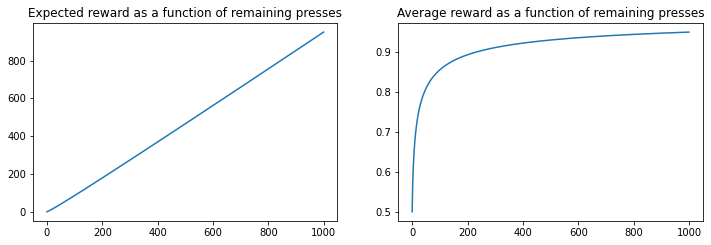

In [6]:
fig = plt.figure(figsize = (12,8))
ax = fig.add_subplot(221)
ax.set_title("Expected reward as a function of remaining presses")
ax.plot(val[:,0,0]);

val_avg = np.copy(val[:,0,0])
val_avg = val_avg/np.arange(1,len(val_avg)+1)

ax = fig.add_subplot(222)
ax.set_title("Average reward as a function of remaining presses")
ax.plot(val_avg);

In case of Bernoulli bandit starting from a flat prior we find the following interesting pattern.
If we take a button for which we have only seen successes before, it is always better to stay with this button.
If we then consider a button for which we have seen some fails (and the amount of successes is greater than the number of fails) then for some small number of remaining presses T it is better to stay with this button. However, for some sufficiently large T it is actually better to move on to the next button right away.

In [7]:
# We demonstrate it for the case where we have seen 5 successes and 1 fail. We see that at some point in time
# it is actually better to move to a new button

n_success = 5
n_fail = 1
print("The time T for which it is better to move on:", np.where(val[:,n_success,n_fail]-val[:,0,0] == 0.0)[0][0])

The time T for which it is better to move on: 189


Here we experimentally test the optimal policy we have derived earlier.

The run_bernoulli_trials is run from C++ library.

In [8]:
run_time = 500
number_of_runs = 10000
button_prior = (1, 1)
policy_prior = (1, 1)

rewards, th_reward = run_bernoulli_trials(run_time, number_of_runs, button_prior=button_prior, 
                                                                      policy_prior=policy_prior)

print("The individual run length is: " + str(run_time))
print("The number of runs is: " + str(number_of_runs))
print("The theoretical reward is: " + str(th_reward))
print("The mean reward is: " + str(np.mean(rewards)))
print("The deviation is: " + str(np.std(rewards)))
print("The deviation of the mean is: " + str(np.std(rewards)/pow(len(rewards), 0.5)))

The individual run length is: 500
The number of runs is: 10000
The theoretical reward is: 465.3042121474984
The mean reward is: 465.2312
The deviation is: 21.141389418862705
The deviation of the mean is: 0.21141389418862705


Here we inspect aspects of individual instances of the optimal policy we have derived earlier.

The record_full_bernoulli_trials is run from C++ library.

In [9]:
run_time = 500
number_of_runs = 10000
button_prior = (1, 1)
policy_prior = (1, 1)

trial_record, th_reward = record_full_bernoulli_trials(run_time, number_of_runs, button_prior=button_prior, 
                                                                      policy_prior=policy_prior)

Out of 10000 runs in total in 9957 runs (or 99.57%) the last button contributed the most
The average contribution of the button with the largest contribution is 88.96 %


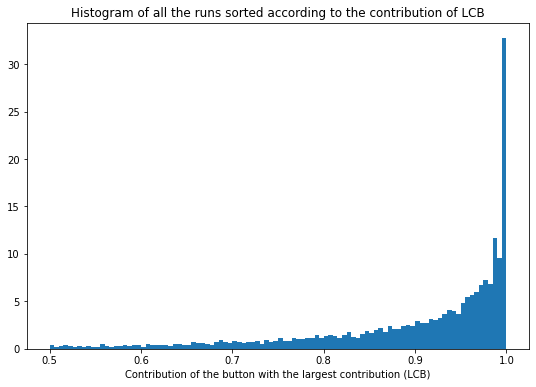

In [10]:
#Total number of button presses
num_presses = np.max(trial_record[:,:,0], axis=1)
#Index of the button with largest contribution
max_button = trial_record[np.arange(len(trial_record)),
                          np.argmax(trial_record[:,:,1], axis=1),0]
#Number of runs where the final button was the button with the largest contribution
num_last_largest_contr = np.count_nonzero(num_presses==max_button)
#Ratio of largest button contribution to total contribution
top_button_to_all = np.max(trial_record[:,:,1], axis=1)/np.sum(trial_record[:,:,3], axis=1)

print("Out of " + str(number_of_runs) + " runs in total in " + str(num_last_largest_contr) + 
            " runs (or " + "%.2f" % (100*num_last_largest_contr/number_of_runs) + 
              "%) the last button contributed the most")
print("The average contribution of the button with the largest contribution is " + 
          "%4.2f" % (100*np.mean(top_button_to_all)) + " %")

plt.figure(figsize=(9,6))
plt.title("Histogram of all the runs sorted according to the contribution of LCB")
plt.xlabel("Contribution of the button with the largest contribution (LCB)")
plt.hist(top_button_to_all, density=True, bins=100, range=(0.5,1));

We see an interesting pattern: in vast majority of cases the last button pressed gives the largest contribution to the total reward. Furthermore, the more presses we have, the more likely the largest contribution will come from the last button. The button with the largest contribution generates most of the reward. Again, the more presses we have, the bigger the ratio of the contribution of the largest button to the total reward, but that number does not change significantly and stays around 85-90%.

Therefore we can say that the optimal strategy the dynamic programming finds is to keep exploring until one finds that one button that generates most of the reward and the optimal policy helps one to guess that button.